# Actividad 9 - Regresión Logística Multinomial
Se predice la marca en cada una de las 3 hojas de `Datos_Complementarios_CLV.xlsx` usando solo las variables numéricas de la hoja.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

## 1. Carga

In [2]:
archivo = 'Datos_Complementarios_CLV.xlsx'
exi = pd.read_excel(archivo, sheet_name=0)
sal = pd.read_excel(archivo, sheet_name=1)
ven = pd.read_excel(archivo, sheet_name=2)
for d in [exi, sal, ven]:
    d.columns = [c.strip() for c in d.columns]
print(exi.shape, sal.shape, ven.shape)

(2951, 6) (55180, 7) (21632, 14)


## 2. Preprocesamiento

In [3]:
# nulos y duplicados
print(exi.isna().sum().sum(), sal.isna().sum().sum(), ven.isna().sum().sum())
print(exi.duplicated().sum(), sal.duplicated().sum(), ven.duplicated().sum())

ven['cp'] = ven['cp'].fillna(ven['cp'].median())
ven = ven.drop_duplicates()
ven = ven[ven['precio_unitario'] > 0]

# marcas en mayuscula
exi['marca'] = exi['marca'].str.strip().str.upper()
sal['MARCA'] = sal['MARCA'].str.strip().str.upper()
ven['marc'] = ven['marc'].str.strip().str.upper()

0 0 492
0 0 185


In [4]:
# transformacion logaritmica de las variables asimetricas
exi['log_existencias'] = np.log1p(exi['existencias'])
exi['log_valor'] = np.log1p(exi['valor_inventario'])
sal['log_salidas'] = np.log1p(sal['SALIDAS'])
ven['log_precio'] = np.log1p(ven['precio_unitario'])
ven['log_unidades'] = np.log1p(ven['total_unidades'])
ven['log_total'] = np.log1p(ven['total_neto'])

# outliers con IQR x3 sobre las variables en log
def quitar_outliers(d, cols):
    ok = pd.Series(True, index=d.index)
    for c in cols:
        q1, q3 = d[c].quantile([.25, .75])
        iqr = q3 - q1
        ok &= d[c].between(q1 - 3 * iqr, q3 + 3 * iqr)
    print('outliers eliminados:', (~ok).sum())
    return d[ok].copy()

exi = quitar_outliers(exi, ['log_existencias', 'log_valor'])
sal = quitar_outliers(sal, ['log_salidas'])
ven = quitar_outliers(ven, ['log_precio', 'log_unidades', 'log_total'])

outliers eliminados: 83
outliers eliminados: 2
outliers eliminados: 1387


## 3. Categorías de marca
Las marcas con menos de 10 registros se agrupan en OTRAS para poder dividir en entrenamiento y prueba.

In [5]:
def agrupar(m):
    n = m.value_counts()
    return m.where(~m.isin(n[n < 10].index), 'OTRAS')

exi['Marca_Existencias'] = agrupar(exi['marca'])
sal['Marca_Salidas'] = agrupar(sal['MARCA'])
ven['Marca_Ventas'] = agrupar(ven['marc'])

analisis = {
    'Marca_Existencias': (exi, ['log_existencias', 'log_valor']),
    'Marca_Salidas': (sal, ['ANO', 'MES', 'log_salidas']),
    'Marca_Ventas': (ven, ['log_precio', 'log_unidades', 'log_total', 'cp']),
}
for v, (d, cols) in analisis.items():
    print(v, d[v].nunique(), 'categorías')

Marca_Existencias 12 categorías
Marca_Salidas 30 categorías
Marca_Ventas 16 categorías


## 4. Regresión logística multinomial
Se usa 70% para entrenar y 30% para probar.

In [6]:
resultados = []
matrices = {}
for v, (d, cols) in analisis.items():
    X, y = d[cols], d[v]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(Xte)
    clases = sorted(y.unique())
    matrices[v] = (confusion_matrix(yte, pred, labels=clases), clases)
    resultados.append({'Variable': v,
                       'Categorías': len(clases),
                       'Exactitud': accuracy_score(yte, pred),
                       'Precisión': precision_score(yte, pred, average='macro', zero_division=0),
                       'Sensibilidad': recall_score(yte, pred, average='macro', zero_division=0)})
    print(v)
    print(classification_report(yte, pred, zero_division=0))

pd.DataFrame(resultados).round(3)

Marca_Existencias
                precision    recall  f1-score   support

        AIDITE       0.79      0.52      0.63        63
AMANN GIRRBACH       0.46      0.51      0.48        91
     ANAX DENT       0.00      0.00      0.00        28
         ASIGA       0.00      0.00      0.00         4
      CREATION       0.00      0.00      0.00        72
          HASS       0.00      0.00      0.00         3
          HUGE       0.96      1.00      0.98        27
        JENSEN       0.00      0.00      0.00        13
         OTRAS       0.00      0.00      0.00        18
       PHROZEN       0.00      0.00      0.00         6
     SCHEFTNER       0.00      0.00      0.00         8
          VITA       0.74      0.96      0.83       528

      accuracy                           0.71       861
     macro avg       0.25      0.25      0.24       861
  weighted avg       0.59      0.71      0.64       861



Marca_Salidas


                precision    recall  f1-score   support

         3DGAR       0.00      0.00      0.00        14
            AG       0.00      0.00      0.00      2238
        AIDITE       0.32      0.08      0.13       977
     ANAX DENT       0.00      0.00      0.00       253
   ARMA DENTAL       0.00      0.00      0.00         7
         ASIGA       0.00      0.00      0.00        75
      CREATION       0.00      0.00      0.00       189
CUTTING FLUIDS       0.00      0.00      0.00         7
   CYBERPUERTA       0.00      0.00      0.00        19
         DEKEM       0.00      0.00      0.00        73
         DENTI       0.00      0.00      0.00        56
         DURRD       0.00      0.00      0.00        18
        EXOCAD       0.00      0.00      0.00        19
          HASS       0.00      0.00      0.00        42
          HUGE       0.00      0.00      0.00       613
           IPD       0.00      0.00      0.00       237
         JENSE       0.00      0.00      0.00  

Marca_Ventas
              precision    recall  f1-score   support

          AG       0.47      0.20      0.29       960
      AIDITE       0.47      0.89      0.62      1356
   ANAX DENT       0.00      0.00      0.00        55
       ASIGA       0.00      0.00      0.00        20
    CREATION       0.00      0.00      0.00        57
       DEKEM       0.00      0.00      0.00         7
      EXOCAD       0.00      0.00      0.00         7
        HUGE       0.95      1.00      0.98        62
         IPD       0.00      0.00      0.00        12
       JENSE       0.00      0.00      0.00       433
       MEDIT       0.74      0.72      0.73        78
       OTRAS       0.00      0.00      0.00        12
       PHROZ       0.00      0.00      0.00        50
      QUATRO       0.00      0.00      0.00        12
        ROKO       0.00      0.00      0.00         8
        VITA       0.93      0.95      0.94      2408

    accuracy                           0.69      5537
   macro avg 

,Variable,Categorías,Exactitud,Precisión,Sensibilidad
0,Marca_Existencias,12,0.711,0.245,0.249
1,Marca_Salidas,30,0.530,0.029,0.036
2,Marca_Ventas,16,0.685,0.223,0.235


## 5. Matrices de confusión
Se muestran las 8 marcas con más registros de cada hoja.

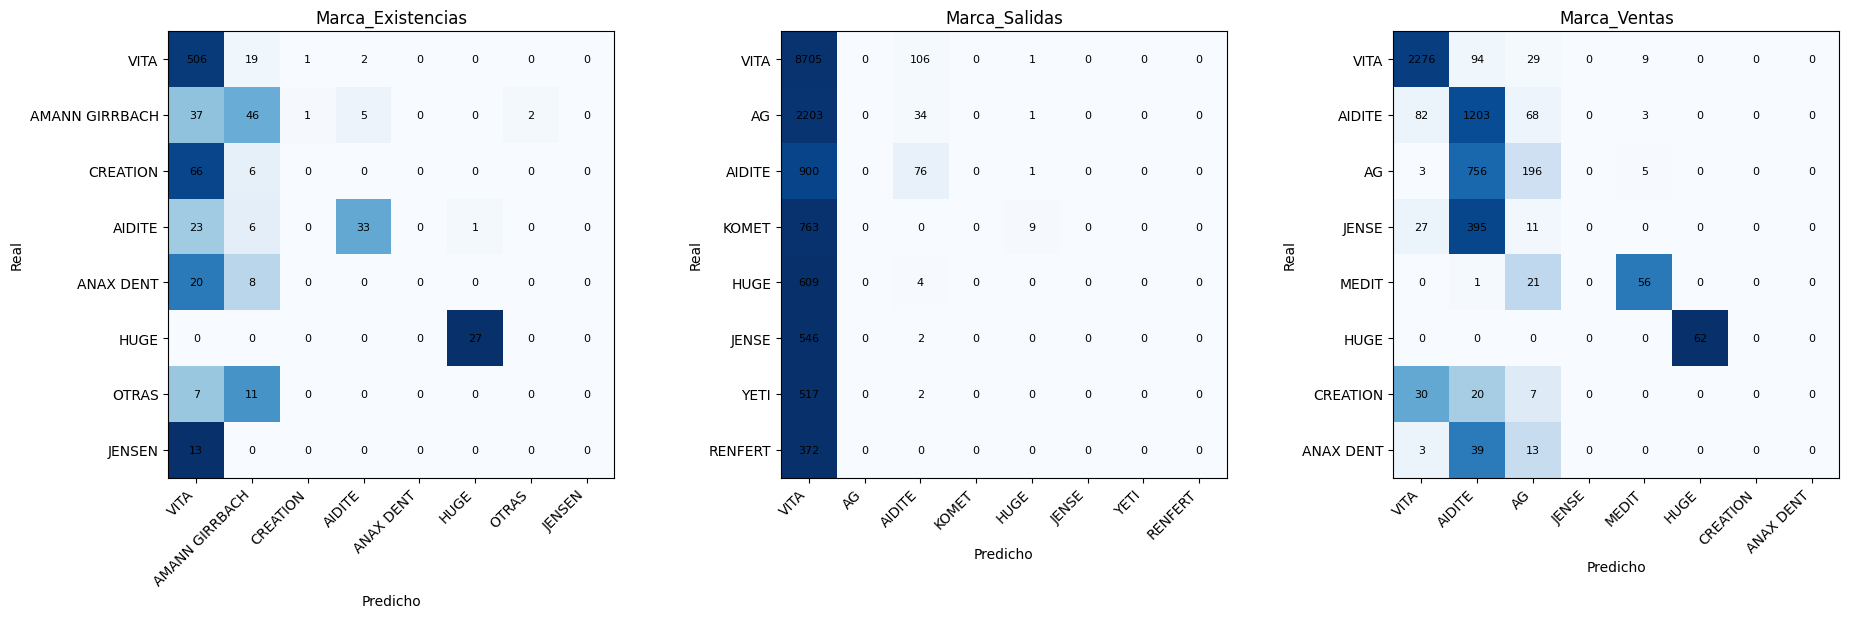

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, v in zip(axes, analisis):
    m, clases = matrices[v]
    n = 8
    top = np.argsort(-m.sum(axis=1))[:n]
    mm = m[np.ix_(top, top)]
    nom = [clases[i] for i in top]
    ax.imshow(mm / m.sum(axis=1)[top][:, None], cmap='Blues')
    ax.set_xticks(range(n))
    ax.set_xticklabels(nom, rotation=45, ha='right')
    ax.set_yticks(range(n))
    ax.set_yticklabels(nom)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, mm[i, j], ha='center', va='center', fontsize=8)
    ax.set_title(v)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
plt.tight_layout()
plt.show()